<a href="https://colab.research.google.com/github/muriloboratto/modern-cuda-c-/blob/main/matrix_multiplication_cpu_cuda_thrust_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Matrix Multiplication Benchmark: Sequential C++ vs Classic CUDA vs Modern CUDA (Thrust)

This Google Colab laboratory compares three implementations of $$C = A × B$$, using double-precision (`double`) arithmetic:

1. **Sequential CPU:** `std::for_each` and a C++ lambda.
2. **Classic CUDA:** explicit `__global__` kernel with a 2D grid and 2D blocks.
3. **Modern CUDA:** Thrust `device_vector`, `transform`, and a device lambda.

The experiment collects **end-to-end elapsed time** (including host↔device copies for GPU variants), computes **speedup relative to sequential CPU**, and plots both metrics. Classic CUDA additionally reports **kernel-only CUDA Event time** for illustration; this must not be compared directly with CPU end-to-end time.

## 1. Runtime and compiler installation

Select **Runtime → Change runtime type → GPU** in Colab. Check availability before proceeding.

In [ ]:
!nvidia-smi
!g++ --version | head -n 1
!nvcc --version

Tue Oct 20 18:11:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Shared experiment settings

The default sizes are deliberately modest for Colab. Dense naïve matrix multiplication costs $O(N^3)$ operations, so large CPU runs may be slow. Change `SIZES`, `REPEATS`, and `BLOCK_SIZE` as appropriate. Block dimensions must satisfy device limits (for example, $16×16$ or $64×64$ on common NVIDIA GPUs).

In [ ]:
SIZES = [512, 1024, 2048, 4096]
REPEATS = 3
BLOCK_SIZE = 64
TIMEOUT_SECONDS = 600
print(f"Sizes: {SIZES}; repetitions: {REPEATS}; CUDA block: {BLOCK_SIZE}x{BLOCK_SIZE}")

Sizes: [512, 1024, 2048, 4096]; repetitions: 3; CUDA block: 64x64


In [ ]:
import subprocess
import math

def execute(program, n, block_size=64):

    cmd = [f"./{program}", str(n)]
    if program == "mm-cuda":
        cmd.append(str(block_size))

    result = subprocess.run(cmd, capture_output=True, text=True, check=True)
    fields = result.stdout.strip().split()

    return {
        "n": int(fields[0]),
        "seconds": float(fields[1])
    }

## 3. `Sequential C++`

Based on the original notebook: a lambda maps a linear output index to row and column and computes one dot product. The reported time measures **only multiplication**, not matrix initialization.

In [ ]:
%%writefile mm-cpu.cpp
#include <algorithm>
#include <chrono>
#include <cstdio>
#include <cstdlib>
#include <numeric>
#include <vector>

void initialization_matrix(double *A, int n)
{
    for (int i = 0; i < n; ++i)
        for (int j = 0; j < n; ++j)
            A[static_cast<size_t>(i)*n+j] = std::rand()%(10-1)*1;
}

void mult_matrix_cpu(const double *A, const double *B, double *C, int n)
{
    std::vector<size_t> indices(static_cast<size_t>(n)*n);
    std::iota(indices.begin(), indices.end(), size_t{0});

    auto multiplication = [=](size_t index)
    {
        const size_t i = index / n, j = index % n;
        double sum = 0.0;

        for (int k = 0; k < n; ++k)
            sum += A[i*n+k] * B[static_cast<size_t>(k)*n+j];

        C[index] = sum;
    };

    std::for_each(indices.begin(), indices.end(), multiplication);
}

int main(int argc, char **argv)
{
    int n = std::atoi(argv[1]);

    size_t elements = static_cast<size_t>(n)*n;
    std::vector<double> A(elements), B(elements), C(elements, 0.0);

    initialization_matrix(A.data(), n);
    initialization_matrix(B.data(), n);

    auto start = std::chrono::steady_clock::now();
          mult_matrix_cpu(A.data(), B.data(), C.data(), n);
    auto stop = std::chrono::steady_clock::now();

    double seconds = std::chrono::duration<double>(stop-start).count();

    std::printf("%d\t%.9f\n", n, seconds);
}

Overwriting mm-cpu.cpp


## 4. `Classic CUDA` — Explcit kernel, grid, blocks and threads

Adapted from the attached `mm-cuda.cu`.

**Fix:** declare `dim3 block` before calculating `dim3 grid`. Every thread computes one output element `C[i,j]` and loops over `k`.

The first timing field measures **end-to-end GPU work** (allocation + copies + kernel + copy back) using `std::chrono`. The second uses **CUDA Events** to measure kernel-only time. GPU errors are checked explicitly.

In [ ]:
%%writefile mm-cuda.cu
#include <cstdio>
#include <cstdlib>
#include <vector>
#include <numeric>
#include <chrono>
#include <cuda_runtime.h>

void initialization_matrix (double *A, int n)
{
    for (int i = 0; i < n; ++i)
        for (int j = 0; j < n; ++j)
            A[static_cast<size_t>(i)*n+j] = std::rand() % (10 - 1) * 1;
}

__global__ void mult_matrix_gpu ( double *A,  double *B, double *C, int n)
{
    int i = blockIdx.y * blockDim.y + threadIdx.y;
    int j = blockIdx.x * blockDim.x + threadIdx.x;

    if (i < n && j < n)
    {
        double sum = 0.0;

        for (int k = 0; k < n; ++k)
            sum += A[static_cast<size_t>(i)*n+k] * B[static_cast<size_t>(k)*n+j];

        C[static_cast<size_t>(i)*n+j] = sum;
    }
}

int main(int argc, char **argv)
{
    int n         = std::atoi(argv[1]);
    int sizeblock = std::atoi(argv[2]);

    size_t elements = static_cast<size_t>(n)*n, bytes = elements*sizeof(double);
    std::vector<double> A(elements), B(elements), C(elements);

    initialization_matrix(A.data(), n);
    initialization_matrix(B.data(), n);

    double *d_A = nullptr, *d_B = nullptr, *d_C = nullptr;
    cudaEvent_t start, stop;

    auto total_start = std::chrono::steady_clock::now();

    cudaMalloc(&d_A, bytes);
    cudaMalloc(&d_B, bytes);
    cudaMalloc(&d_C, bytes);

    cudaMemcpy(d_A, A.data(), bytes, cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, B.data(), bytes, cudaMemcpyHostToDevice);

    dim3 block(sizeblock, sizeblock);
    dim3 grid((n + block.x - 1) / block.x, (n + block.y - 1) / block.y);

    cudaEventCreate(&start);
    cudaEventCreate(&stop);
    cudaEventRecord(start);

            mult_matrix_gpu<<<grid, block>>>(d_A, d_B, d_C, n);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);
    float milliseconds = 0.0f;
    cudaEventElapsedTime(&milliseconds, start, stop);

    cudaMemcpy(C.data(), d_C, bytes, cudaMemcpyDeviceToHost);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);
    cudaFree(d_A);
    cudaFree(d_B);
    cudaFree(d_C);

    auto total_stop = std::chrono::steady_clock::now();
    double seconds = std::chrono::duration<double>(total_stop-total_start).count();

    std::printf("%d\t%.9f\n", n, seconds);
}

Overwriting mm-cuda.cu


## 5. `Modern CUDA` — Thrust

The origial notebook's CUDA Thrust approach is preserved: `thrust::transform` applies a `__device__` lambda over output indices. Thrust manages GPU allocation and the output copy. The timed region includes GPU allocations, H2D copies, the transformation, D2H copy, and cleanup; the CUDA context is initialized before timing.

In [ ]:
%%writefile mm-thrust.cu
#include <cstdio>
#include <cstdlib>
#include <vector>
#include <numeric>
#include <chrono>
#include <cuda_runtime.h>

#include <thrust/device_vector.h>
#include <thrust/transform.h>
#include <thrust/iterator/counting_iterator.h>
#include <thrust/device_ptr.h>
#include <thrust/system/cuda/execution_policy.h>

void initialization_matrix(double *A, int n)
{
    for (int i = 0; i < n; ++i)
        for (int j = 0; j < n; ++j)
            A[static_cast<size_t>(i)*n+j] = std::rand() % (10 - 1) * 1;
}

void mult_matrix_gpu(const thrust::device_vector<double>& A,
                     const thrust::device_vector<double>& B,
                     thrust::device_vector<double>& C, int n)
{
    const double *a = thrust::raw_pointer_cast(A.data());
    const double *b = thrust::raw_pointer_cast(B.data());

    auto multiplication = [=] __device__ (size_t index) -> double
    {
        size_t i = index/n, j = index % n;

        double sum = 0.0;

        for (int k = 0; k < n; ++k)
            sum += a[i*n+k] * b[static_cast<size_t>(k)*n+j];

        return sum;
    };

    auto first = thrust::make_counting_iterator<size_t>(0);
    thrust::transform(thrust::cuda::par, first, first+C.size(), C.begin(), multiplication);
}

int main(int argc, char **argv)
{
    int n = std::atoi(argv[1]);

    size_t elements = static_cast<size_t>(n)*n;
    std::vector<double> A(elements), B(elements);

    std::srand(42);
    initialization_matrix(A.data(), n);
    initialization_matrix(B.data(), n);

    auto start = std::chrono::steady_clock::now();
    std::vector<double> C(elements);
    {
        thrust::device_vector<double> d_A(A.begin(), A.end());
        thrust::device_vector<double> d_B(B.begin(), B.end());
        thrust::device_vector<double> d_C(elements);
        mult_matrix_gpu(d_A, d_B, d_C, n);
        thrust::copy(d_C.begin(), d_C.end(), C.begin());
    }

    auto stop = std::chrono::steady_clock::now();
    double seconds = std::chrono::duration<double>(stop-start).count();

    std::printf("%d\t%.9f\n", n, seconds);
}

Overwriting mm-thrust.cu


## 6. `Compilation`

In [ ]:
import subprocess
commands = [
    ["g++", "-O3", "-std=c++17", "mm-cpu.cpp", "-o", "mm-cpu"],
    ["nvcc", "-O3", "-std=c++17", "mm-cuda.cu", "-o", "mm-cuda"],
    ["nvcc", "-O3", "-std=c++17", "--extended-lambda", "mm-thrust.cu", "-o", "mm-thrust"],
]
for command in commands:
    print("$", " ".join(command), flush=True)
    subprocess.run(command, check=True)

$ g++ -O3 -std=c++17 mm-cpu.cpp -o mm-cpu
$ nvcc -O3 -std=c++17 mm-cuda.cu -o mm-cuda
$ nvcc -O3 -std=c++17 --extended-lambda mm-thrust.cu -o mm-thrust


## 7. `Experimentation Benchmark`

In [ ]:
import pandas as pd

programs = {
    "Sequential CPU": "mm-cpu",
    "Classic CUDA": "mm-cuda",
    "Modern CUDA (Thrust)": "mm-thrust"
}

records = []

for n in SIZES:
    print(f"Benchmark N={n}", flush=True)

    for label, executable in programs.items():
        execute(executable, n)  # Warm-up

        for repetition in range(1, REPEATS + 1):
            r = execute(executable, n)

            records.append({
                "N": n,
                "Implementation": label,
                "Repetition": repetition,
                "Time (s)": r["seconds"]
            })

raw = pd.DataFrame(records)

display(raw.head(12))


Benchmark N=512
Benchmark N=1024
Benchmark N=2048
Benchmark N=4096


In [ ]:
summary = raw.groupby(["N", "Implementation"], as_index=False).agg(
    **{
        "Median time (s)": ("Time (s)", "median"),
        "Std dev (s)": ("Time (s)", "std")
    }
)

reference = summary[summary["Implementation"] == "Sequential CPU"].set_index("N")["Median time (s)"]
summary["Speedup vs CPU"] = summary.apply(
    lambda row: reference.loc[row["N"]] / row["Median time (s)"], axis=1
)
display(summary.round(6))
summary.to_csv("mm_benchmark_summary.csv", index=False)
raw.to_csv("mm_benchmark_raw.csv", index=False)

,N,Implementation,Median time (s),Std dev (s),Speedup vs CPU
0,128,Classic CUDA,0.174731,0.020299,0.017425
1,128,Modern CUDA (Thrust),0.151196,0.003002,0.020137
2,128,Sequential CPU,0.003045,0.000166,1.000000
3,256,Classic CUDA,0.150178,0.003922,0.150421
4,256,Modern CUDA (Thrust),0.155519,0.006542,0.145256
5,256,Sequential CPU,0.022590,0.000393,1.000000
6,512,Classic CUDA,0.177008,0.012195,2.301916
7,512,Modern CUDA (Thrust),0.157124,0.002485,2.593228
8,512,Sequential CPU,0.407459,0.022340,1.000000
9,1024,Classic CUDA,0.193446,0.008606,17.386614


## 8. Chart — Execution time

The log-scaled y-axis helps compare very different execution times. All curves use end-to-end times as defined above.

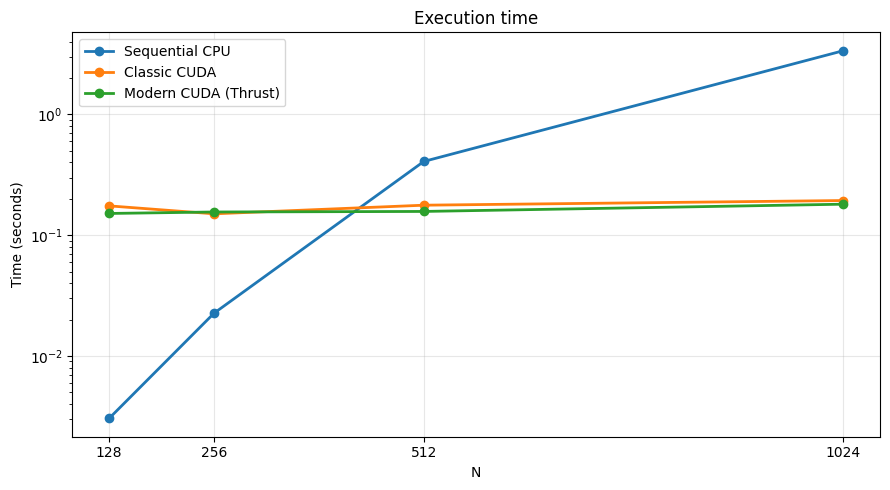

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
for label in programs:
    data = summary[summary["Implementation"] == label].sort_values("N")
    ax.plot(data["N"], data["Median time (s)"], marker="o", linewidth=2, label=label)
ax.set(xlabel="N", ylabel="Time (seconds)",
       title="Execution time")
ax.set_yscale("log")
ax.set_xticks(SIZES)
ax.grid(True, alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig("mm_execution_time.png", dpi=160)
plt.show()

## 11. Chart — Speedup over sequential CPU

A horizontal line at 1× indicates parity with CPU. A GPU speedup below 1× means it is slower than CPU for that size.

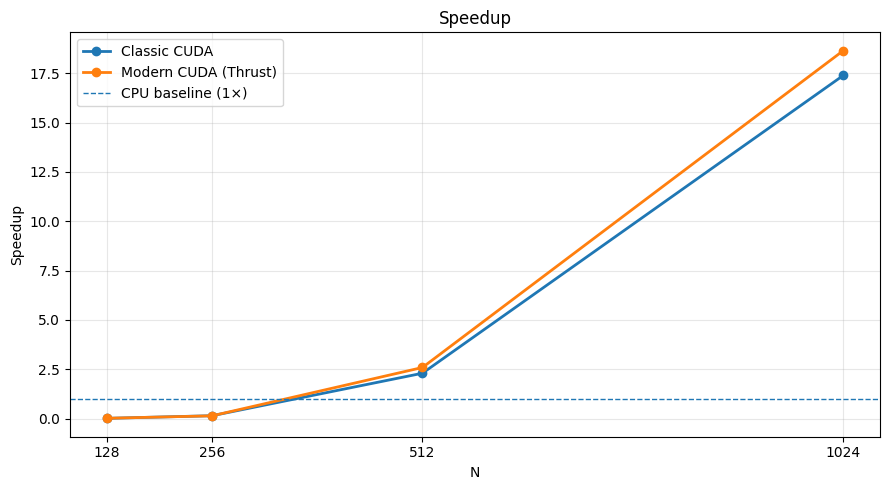

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
for label in ("Classic CUDA", "Modern CUDA (Thrust)"):
    data = summary[summary["Implementation"] == label].sort_values("N")
    ax.plot(data["N"], data["Speedup vs CPU"], marker="o", linewidth=2, label=label)
ax.axhline(1, linestyle="--", linewidth=1, label="CPU baseline (1×)")
ax.set(xlabel="N", ylabel="Speedup",
       title="Speedup")
ax.set_xticks(SIZES)
ax.grid(True, alpha=.3)
ax.legend()
plt.tight_layout()
plt.savefig("mm_speedup.png", dpi=160)
plt.show()